In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We study the generalization properties of deep...,0.2340,0.0576,0.1766,0.8035,0.8011,0.8023,1,3,5,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We propose a novel 3D convolutional neural net...,0.2609,0.0933,0.1739,0.8750,0.8232,0.8483,4,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We propose a formalism for the specification o...,0.2642,0.0650,0.1348,0.8146,0.8467,0.8304,4,7,7,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


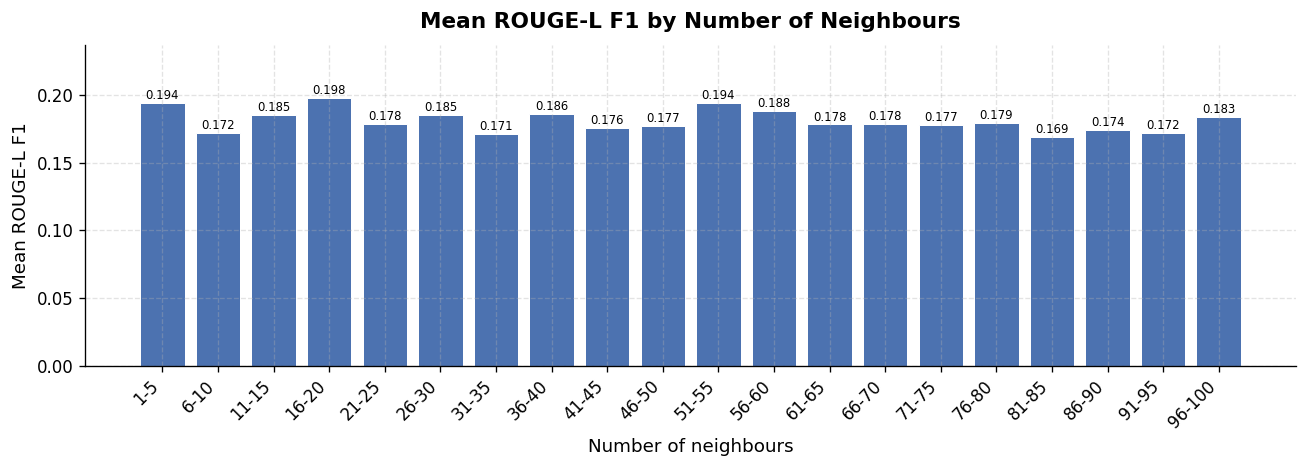

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

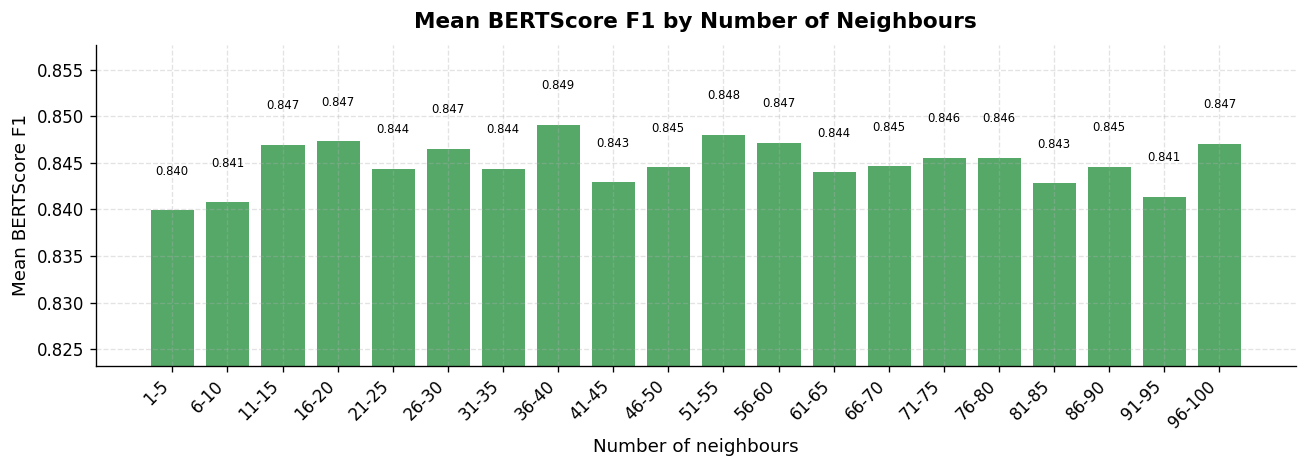

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

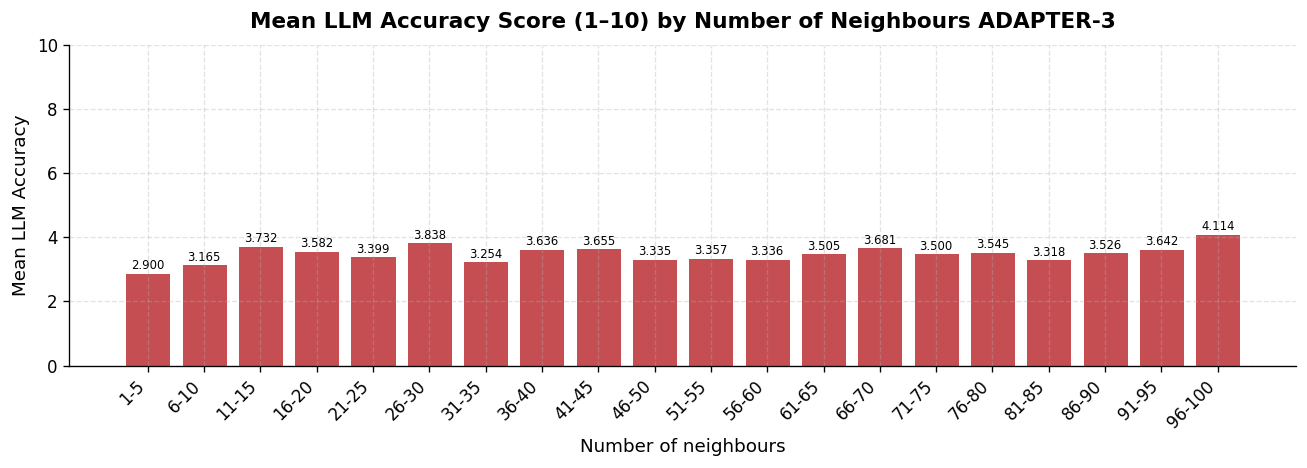

3.5195767195767194
3.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

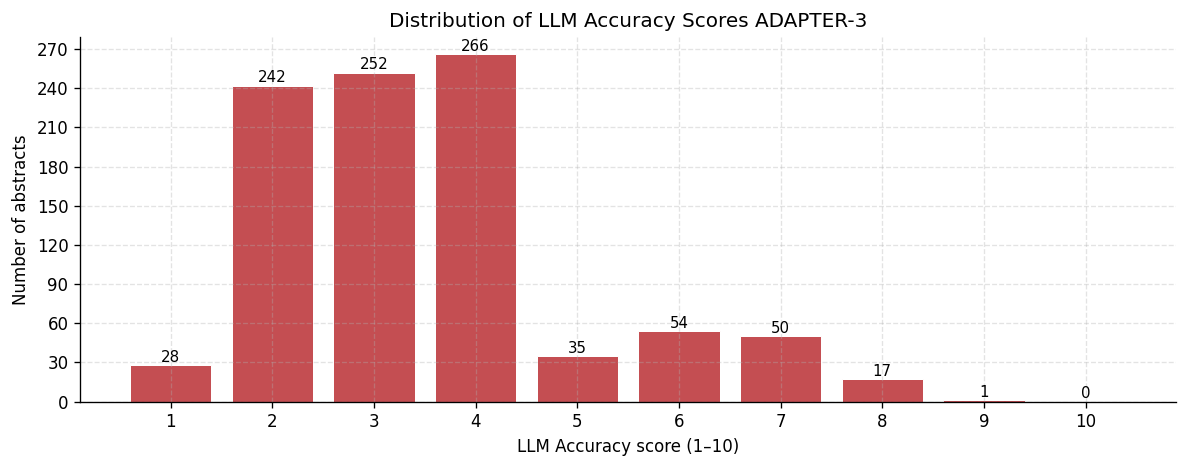

llm_accuracy
1      28
2     242
3     252
4     266
5      35
6      54
7      50
8      17
9       1
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

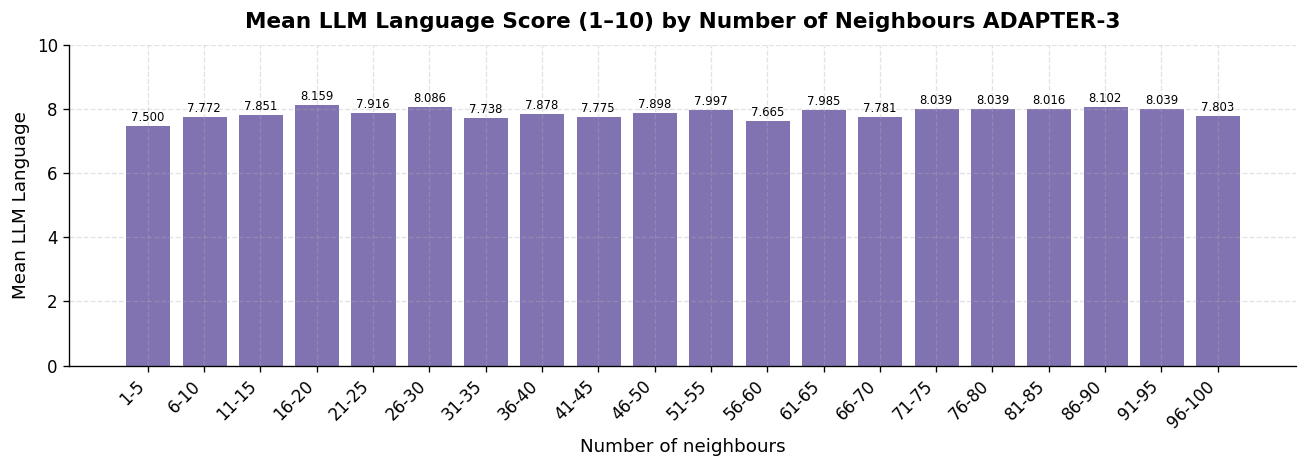

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

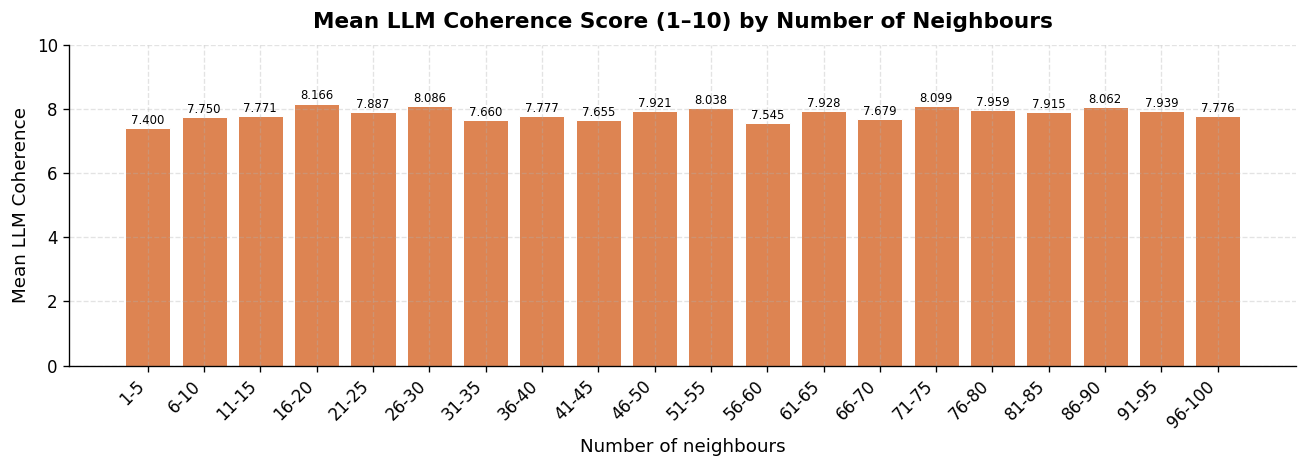

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

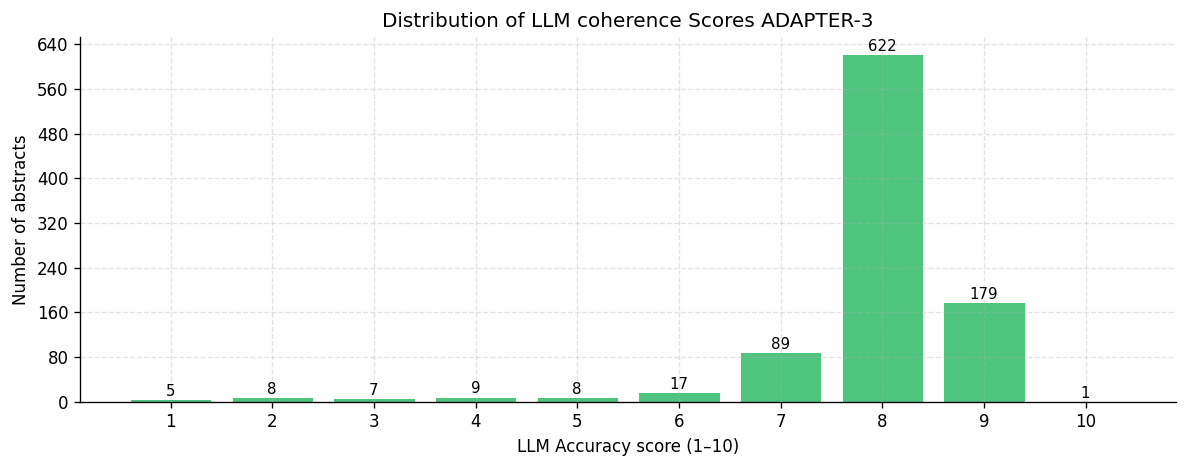

llm_coherence
1       5
2       8
3       7
4       9
5       8
6      17
7      89
8     622
9     179
10      1
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 13 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      3.5196
Mean llm_accuracy (excluding 1,2): 3.5268


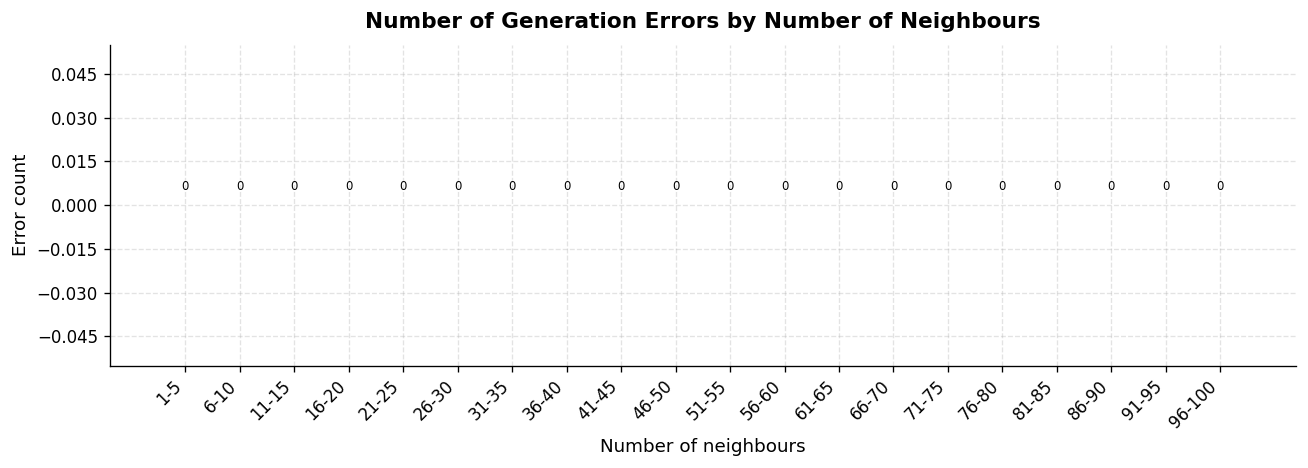

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_20864/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,17247,"Distributed deep learning becomes very common to reduce the overall training time by exploiting multiple computing devices (e.g., GPUs/TPUs) as the size of deep models and data sets increases. However, data communication between computing devices could be a potential bottleneck to limit the system scalability. How to address the communication problem in distributed deep learning is becoming a hot research topic recently. In this paper, we provide a comprehensive survey of the communication-efficient distributed training algorithms in both system-level and algorithmic-level optimizations. In the system-level, we demystify the system design and implementation to reduce the communication cost. In algorithmic-level, we compare different algorithms with theoretical convergence bounds and communication complexity. Specifically, we first propose the taxonomy of data-parallel distributed training algorithms, which contains four main dimensions: communication synchronization, system architectures, compression techniques, and parallelism of communication and computing. Then we discuss the studies in addressing the problems of the four dimensions to compare the communication cost. We further compare the convergence rates of different algorithms, which enable us to know how fast the algorithms can converge to the solution in terms of iterations. According to the system-level communication cost analysis and theoretical convergence speed comparison, we provide the readers to understand what algorithms are more efficient under specific distributed environments and extrapolate potential directions for further optimizations.","Distributed training of deep neural networks is often limited by the communication bandwidth between workers. In this paper, we propose a novel communication compression method, named Gradient Thresholding (GT), to reduce the communication cost. GT compresses the gradient by thresholding the small gradient values to zero. We show that GT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can be applied to both synchronous and asynchronous distributed training. We also propose a novel thresholding strategy, named Layer-wise Thresholding (LT), to adapt the threshold to the layer-wise gradient distribution. We show that LT can",1
1,51722,"To learn models or features that generalize across tasks and domains is one of the grand goals of machine learning. In this paper, we propose to use cross-domain, cross-task data as validation objective for hyper-parameter optimization (HPO) to improve on this goal. Given a rich enough search space, optimization of hyper-parameters learn features that maximize validation performance and, due to the objective, generalize across tasks and domains. We demonstrate the effectiveness of this strategy on few-shot ima

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_20864/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,1089,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","We study the generalization properties of deep neural networks (DNNs) trained with different optimization algorithms. We show that the optimization algorithm has a significant impact on the generalization performance of DNNs. In particular, we find that the generalization performance of DNNs trained with adaptive gradient methods (e.g., Adam) is worse than that of DNNs trained with stochastic gradient descent (SGD). We also find that the generalization performance of DNNs trained with SGD is better than that of DNNs trained with other optimization algorithms. We show that the generalization performance of DNNs trained with different optimization algorithms is related to the flatness of the minima of the loss function. We also show that the generalization performance of DNNs trained with different optimization algorithms is related to the sharpness of the minima of the loss function. We show that the generalization performance of DNNs trained with different optimization algorithms is related to the curvature of the loss function. We show that the generalization performance of DNNs trained with different optimization algorithms is related to the volume of the basin of attraction of the minima of the loss function. We show that the generalization performance of DNNs trained with different optimization algorithms is related to the volume of the basin of attraction of the minima of the loss function. We show that the generalization performance of DNNs trained with different optimization algorithms is related to the volume of the basin of attraction of the minima of the loss function. We show that the generalization performance of DNNs trained with different",1
1,155504,"In the NP-hard Edge Dominating Set problem (EDS) we are given a graph $G=(V,E)$ and an integer $k$, and need to determine whether there is a set $F\subseteq E$ of at most $k$ edges that are incident with all (other) edges of $G$. It is known that this problem is fixed-parameter tractable and admits a polynomial kernel when parameterized by $k$. A caveat for this parameter is that it needs to be large, i.e., at least equal to half the size of a maximum matching of $G$, for instances not to be trivially negative. Motivated by this, we study the existence of polynomial kernels for EDS when parameterized by structural parameters that may be much smaller than $k$. #R##N#Unfortunately, at first glance this looks rather hopeless: Even when parameterized by the deletion distance to a disjoint union of paths $P_3$ of length two there is no polynomial kernelization (under standard assumptions), ruling out polynomial kernels for many smaller parameters like the feedback vertex set size. In

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


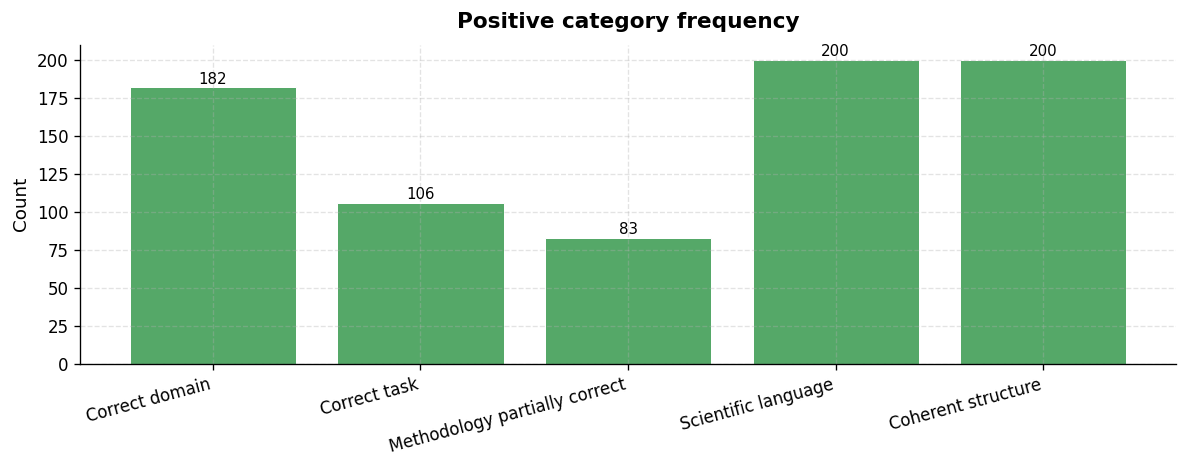

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()